In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

# Load integrated research dataset
research_df = pd.read_parquet(
    "../data/processed/research_analysis_dataset.parquet"
)

# Load embeddings
embeddings = np.load(
    "../data/processed/paper_embeddings.npy"
)

print("Research dataset:", research_df.shape)
print("Embeddings:", embeddings.shape)

print("\nColumns:")
print(research_df.columns.tolist())

print("\nFirst 5 papers:")
display(
    research_df[
        [
            "paper_id",
            "title",
            "year",
            "citation_count",
            "topic_name",
            "community"
        ]
    ].head()
)

Research dataset: (767, 12)
Embeddings: (767, 384)

Columns:
['paper_id', 'title', 'year', 'citation_count', 'topic_id', 'topic_name', 'degree_centrality', 'betweenness_centrality', 'pagerank', 'community', 'year_median_citations', 'relative_citations']

First 5 papers:


,paper_id,title,year,citation_count,topic_name,community
0,https://openalex.org/W4384389802,A Comprehensive Overview of Large Language Models,2023,368,Surveys & Research Directions,0
1,https://openalex.org/W4390602555,A Comprehensive Survey of Hallucination Mitiga...,2024,122,Surveys & Research Directions,17
2,https://openalex.org/W4403578737,A Comprehensive Survey of Retrieval-Augmented ...,2024,23,Surveys & Research Directions,51
3,https://openalex.org/W4407164528,A Comprehensive Survey of Retrieval-Augmented ...,2025,28,Surveys & Research Directions,3
4,https://openalex.org/W4416291690,A Comprehensive Survey on Multimodal RAG: All ...,2025,2,Surveys & Research Directions,7


In [8]:
# Load embedding model once

from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

print("Embedding model loaded.")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7804.41it/s]


Embedding model loaded.


In [9]:
# Semantic search function

def search_papers(query, top_k=10):
    """
    Find papers semantically similar to a natural-language query.
    """

    query_embedding = model.encode(
        [query],
        normalize_embeddings=True
    )

    similarities = cosine_similarity(
        query_embedding,
        embeddings
    )[0]

    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = research_df.iloc[top_indices].copy()

    results["similarity"] = similarities[top_indices]

    return results[
        [
            "paper_id",
            "title",
            "year",
            "citation_count",
            "relative_citations",
            "topic_name",
            "community",
            "degree_centrality",
            "betweenness_centrality",
            "pagerank",
            "similarity"
        ]
    ].reset_index(drop=True)

In [10]:
# Test semantic search

results = search_papers(
    "graph based retrieval augmented generation",
    top_k=10
)

display(results)

,paper_id,title,year,citation_count,relative_citations,topic_name,community,degree_centrality,betweenness_centrality,pagerank,similarity
0,https://openalex.org/W4411119292,Knowledge Graph-Guided Retrieval Augmented Gen...,2025,76,6.909091,Computational Linguistics,17,0.077023,0.005775,0.002229,0.800015
1,https://openalex.org/W4412889884,SeaKR: Self-aware Knowledge Retrieval for Adap...,2025,24,2.181818,NLP / Computational Linguistics,17,0.066580,0.000997,0.001852,0.759055
2,https://openalex.org/W4404782883,Searching for Best Practices in Retrieval-Augm...,2024,109,3.516129,NLP / Computational Linguistics,17,0.046997,0.000700,0.001603,0.734508
3,https://openalex.org/W4416379250,Graph Retrieval-Augmented Generation: A Survey,2025,145,13.181818,Surveys & Research Directions,6,0.096606,0.001986,0.002573,0.708417
4,https://openalex.org/W4411119426,"Fact, Fetch, and Reason: A Unified Evaluation ...",2025,21,1.909091,Computational Linguistics,17,0.060052,0.003205,0.001995,0.701093
5,https://openalex.org/W4226069413,A Survey on Retrieval-Augmented Text Generation,2022,71,0.606838,Surveys & Research Directions,17,0.056136,0.000317,0.001553,0.699357
6,https://openalex.org/W4407129024,GFM-RAG: Graph Foundation Model for Retrieval ...,2025,7,0.636364,Graph RAG & Knowledge Graphs,6,0.155352,0.007888,0.004130,0.697280
7,https://openalex.org/W4389519118,Active Retrieval Augmented Generation,2023,454,6.219178,NLP / Computational Linguistics,17,0.037859,0.001294,0.001333,0.694989
8,https://openalex.org/W4412889887,Knowledge Graph Retrieval-Augmented Generation...,2025,55,5.000000,NLP / Computational Linguistics,17,0.007833,0.000014,0.000433,0.694590
9,https://openalex.org/W4416035020,D-RAG: Differentiable Retrieval-Augmented Gene...,2025,5,0.454545,NLP / Computational Linguistics,6,0.061358,0.000863,0.001628,0.690017


,topic_name,paper_count
0,NLP / Computational Linguistics,5
1,Computational Linguistics,2
2,Surveys & Research Directions,2
3,Graph RAG & Knowledge Graphs,1


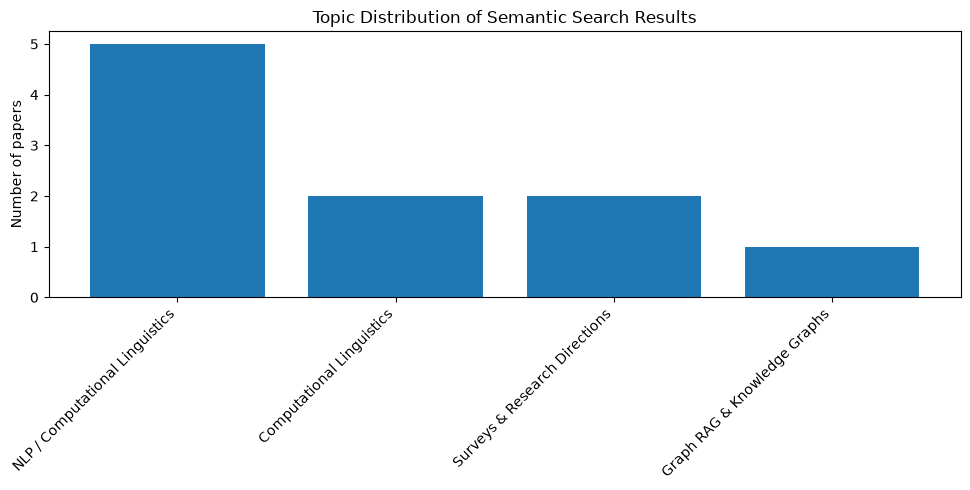

In [11]:
# Analyze topic distribution in search results

topic_distribution = (
    results["topic_name"]
    .value_counts()
    .reset_index()
)

topic_distribution.columns = ["topic_name", "paper_count"]

display(topic_distribution)

plt.figure(figsize=(10, 5))

plt.bar(
    topic_distribution["topic_name"],
    topic_distribution["paper_count"]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of papers")
plt.title("Topic Distribution of Semantic Search Results")
plt.tight_layout()
plt.show()

,community,paper_count
0,17,7
1,6,3


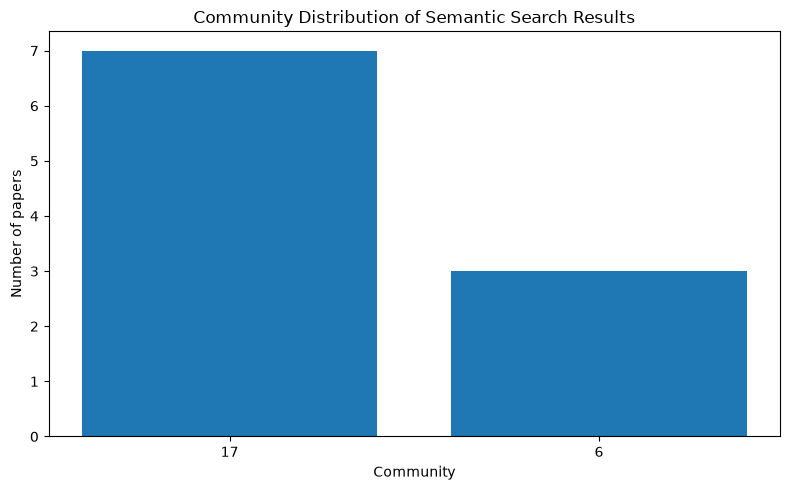

In [12]:
# Analyze community distribution in search results

community_distribution = (
    results["community"]
    .value_counts()
    .reset_index()
)

community_distribution.columns = ["community", "paper_count"]

display(community_distribution)

plt.figure(figsize=(8, 5))

plt.bar(
    community_distribution["community"].astype(str),
    community_distribution["paper_count"]
)

plt.xlabel("Community")
plt.ylabel("Number of papers")
plt.title("Community Distribution of Semantic Search Results")
plt.tight_layout()
plt.show()

In [13]:
# Summarize semantic similarity by network community

community_profile = (
    results
    .groupby("community")
    .agg(
        paper_count=("paper_id", "count"),
        mean_similarity=("similarity", "mean"),
        max_similarity=("similarity", "max"),
        mean_citations=("citation_count", "mean"),
        mean_pagerank=("pagerank", "mean")
    )
    .sort_values("mean_similarity", ascending=False)
)

display(community_profile)

,paper_count,mean_similarity,max_similarity,mean_citations,mean_pagerank
community,,,,,
17,7,0.726230,0.800015,115.714286,0.001571
6,3,0.698571,0.708417,52.333333,0.002777


In [14]:
# Inspect papers belonging to a selected research community

selected_community = 17

community_papers = (
    research_df[
        research_df["community"] == selected_community
    ]
    .sort_values("citation_count", ascending=False)
)

display(
    community_papers[
        [
            "title",
            "year",
            "citation_count",
            "relative_citations",
            "topic_name",
            "degree_centrality",
            "betweenness_centrality",
            "pagerank"
        ]
    ].head(15)
)

,title,year,citation_count,relative_citations,topic_name,degree_centrality,betweenness_centrality,pagerank
198,Dense Passage Retrieval for Open-Domain Questi...,2020,3352,16.351220,NLP / Computational Linguistics,0.003916,0.000000,0.000322
36,A Survey on Hallucination in Large Language Mo...,2024,2111,68.096774,Surveys & Research Directions,0.022193,0.000068,0.001116
585,RAGAs: Automated Evaluation of Retrieval Augme...,2024,487,15.709677,Computational Linguistics,0.062663,0.003044,0.002014
54,Active Retrieval Augmented Generation,2023,454,6.219178,NLP / Computational Linguistics,0.037859,0.001294,0.001333
422,Large Legal Fictions: Profiling Legal Hallucin...,2024,286,9.225806,Surveys & Research Directions,0.001305,0.000000,0.000312
675,Siren's Song in the AI Ocean: A Survey on Hall...,2023,239,3.273973,Surveys & Research Directions,0.009138,0.000020,0.000645
56,Adaptive-RAG: Learning to Adapt Retrieval-Augm...,2024,218,7.032258,Computational Linguistics,0.022193,0.000150,0.000763
603,REPLUG: Retrieval-Augmented Black-Box Language...,2024,188,6.064516,Computational Linguistics,0.020888,0.000034,0.000826
320,Generation-Augmented Retrieval for Open-Domain...,2021,145,1.094340,NLP / Computational Linguistics,0.054830,0.001198,0.001618
342,Hallucination Mitigation for Retrieval-Augment...,2025,133,12.090909,Surveys & Research Directions,0.028721,0.001648,0.001277


In [15]:
# Inspect the second community reached by the search

selected_community = 6

community_6_papers = (
    research_df[
        research_df["community"] == selected_community
    ]
    .sort_values("citation_count", ascending=False)
)

display(
    community_6_papers[
        [
            "title",
            "year",
            "citation_count",
            "relative_citations",
            "topic_name",
            "degree_centrality",
            "betweenness_centrality",
            "pagerank"
        ]
    ].head(15)
)

,title,year,citation_count,relative_citations,topic_name,degree_centrality,betweenness_centrality,pagerank
434,LightRAG: Simple and Fast Retrieval-Augmented ...,2025,153,13.909091,Core RAG & Retrieval,0.107050,0.000720,0.002722
335,Graph Retrieval-Augmented Generation: A Survey,2025,145,13.181818,Surveys & Research Directions,0.096606,0.001986,0.002573
135,Biomedical knowledge graph-optimized prompt ge...,2024,134,4.322581,Graph RAG & Knowledge Graphs,0.054830,0.003133,0.001732
35,A survey on augmenting knowledge graphs (KGs) ...,2024,128,4.129032,Surveys & Research Directions,0.002611,0.000000,0.000310
356,HybridRAG: Integrating Knowledge Graphs and Ve...,2024,124,4.000000,Graph RAG & Knowledge Graphs,0.049608,0.007331,0.001626
289,"Extract, Define, Canonicalize: An LLM-based Fr...",2024,112,3.612903,LLM Training & Fine-Tuning,0.011749,0.000000,0.000542
406,KRAGEN: a knowledge graph-enhanced RAG framewo...,2024,107,3.451613,Graph RAG & Knowledge Graphs,0.148825,0.013785,0.004192
742,Unifying Large Language Models and Knowledge G...,2023,101,1.383562,Graph RAG & Knowledge Graphs,0.020888,0.001457,0.000952
240,Empowering LLMs by hybrid retrieval-augmented ...,2025,100,9.090909,Graph RAG & Knowledge Graphs,0.023499,0.000369,0.000926
153,CareerX: A Retrieval-Augmented Generation Fram...,2023,100,1.369863,Agentic RAG & Multi-Agent Systems,0.001305,0.000000,0.000418


In [16]:
# Compare the two communities reached by the query

community_comparison = (
    results
    .groupby("community")
    .agg(
        papers=("paper_id", "count"),
        mean_similarity=("similarity", "mean"),
        mean_citations=("citation_count", "mean"),
        mean_relative_citations=("relative_citations", "mean"),
        mean_degree=("degree_centrality", "mean"),
        mean_betweenness=("betweenness_centrality", "mean"),
        mean_pagerank=("pagerank", "mean")
    )
    .sort_values("mean_similarity", ascending=False)
)

display(community_comparison)

,papers,mean_similarity,mean_citations,mean_relative_citations,mean_degree,mean_betweenness,mean_pagerank
community,,,,,,,
17,7,0.726230,115.714286,3.763164,0.050354,0.001757,0.001571
6,3,0.698571,52.333333,4.757576,0.104439,0.003579,0.002777


In [19]:
# Research Explorer

def explore_research(query, top_k=10):
    """
    Explore a research question across the ResearchGraph corpus.

    Returns:
    - semantically similar papers
    - topic distribution
    - community distribution
    - summary statistics
    """

    search_results = search_papers(
        query,
        top_k=top_k
    )

    print("=" * 80)
    print(f"Research query: {query}")
    print("=" * 80)

    # --------------------------------------------------
    # 1. Top matching papers
    # --------------------------------------------------

    print("\nTop matching papers:")

    display(
        search_results[
            [
                "title",
                "year",
                "citation_count",
                "topic_name",
                "community",
                "similarity"
            ]
        ]
    )

    # --------------------------------------------------
    # 2. Topic distribution
    # --------------------------------------------------

    print("\nTopic distribution:")

    topic_summary = (
        search_results["topic_name"]
        .value_counts()
        .rename_axis("topic")
        .reset_index(name="paper_count")
    )

    display(topic_summary)

    # --------------------------------------------------
    # 3. Community distribution
    # --------------------------------------------------

    print("\nCommunity distribution:")

    community_summary = (
        search_results["community"]
        .value_counts()
        .rename_axis("community")
        .reset_index(name="paper_count")
    )

    display(community_summary)

    # --------------------------------------------------
    # 4. Query-level summary
    # --------------------------------------------------

    dominant_community = community_summary.iloc[0]["community"]
    dominant_community_count = community_summary.iloc[0]["paper_count"]

    mean_similarity = search_results["similarity"].mean()

    print("\nQuery summary:")
    print(f"Mean semantic similarity: {mean_similarity:.4f}")
    print(
        f"Most represented community: "
        f"{dominant_community} "
        f"({dominant_community_count}/{len(search_results)} papers)"
    )

    return search_results

In [20]:
explorer_results = explore_research(
    "knowledge graph enhanced retrieval augmented generation",
    top_k=10
)

Research query: knowledge graph enhanced retrieval augmented generation

Top matching papers:


,title,year,citation_count,topic_name,community,similarity
0,Knowledge Graph-Guided Retrieval Augmented Gen...,2025,76,Computational Linguistics,17,0.807778
1,SeaKR: Self-aware Knowledge Retrieval for Adap...,2025,24,NLP / Computational Linguistics,17,0.761878
2,GFM-RAG: Graph Foundation Model for Retrieval ...,2025,7,Graph RAG & Knowledge Graphs,6,0.731387
3,Best Practices for Constructing Knowledge Grap...,2025,3,Core RAG & Retrieval,6,0.715679
4,WeKnow-RAG: An Adaptive Approach for Retrieval...,2024,7,Core RAG & Retrieval,6,0.706144
5,A Survey of Graph Retrieval-Augmented Generati...,2025,14,Surveys & Research Directions,6,0.703794
6,D-RAG: Differentiable Retrieval-Augmented Gene...,2025,5,NLP / Computational Linguistics,6,0.703582
7,Knowledge Graph Retrieval-Augmented Generation...,2025,55,NLP / Computational Linguistics,17,0.702632
8,Research on the construction and application o...,2025,18,Graph RAG & Knowledge Graphs,6,0.696259
9,Enhancing Retrieval-Augmented Large Language M...,2023,184,Question Answering & Retrieval,51,0.682077



Topic distribution:


,topic,paper_count
0,NLP / Computational Linguistics,3
1,Graph RAG & Knowledge Graphs,2
2,Core RAG & Retrieval,2
3,Computational Linguistics,1
4,Surveys & Research Directions,1
5,Question Answering & Retrieval,1



Community distribution:


,community,paper_count
0,6,6
1,17,3
2,51,1



Query summary:
Mean semantic similarity: 0.7211
Most represented community: 6 (6/10 papers)


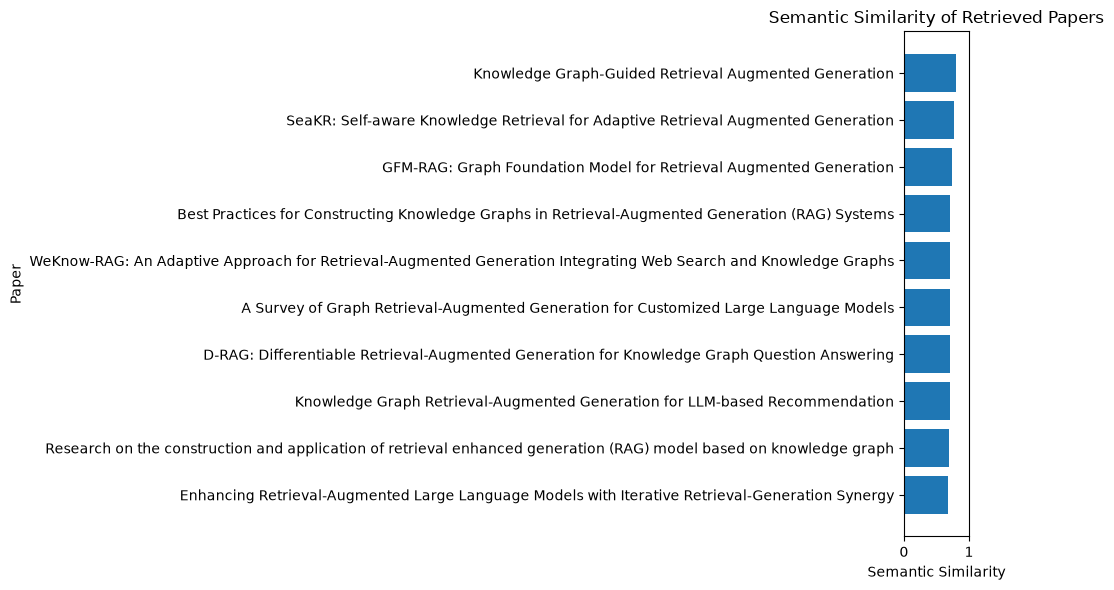

In [21]:
# Visualize semantic similarity of retrieved papers

plt.figure(figsize=(10, 6))

plt.barh(
    explorer_results["title"][::-1],
    explorer_results["similarity"][::-1]
)

plt.xlabel("Semantic Similarity")
plt.ylabel("Paper")
plt.title("Semantic Similarity of Retrieved Papers")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

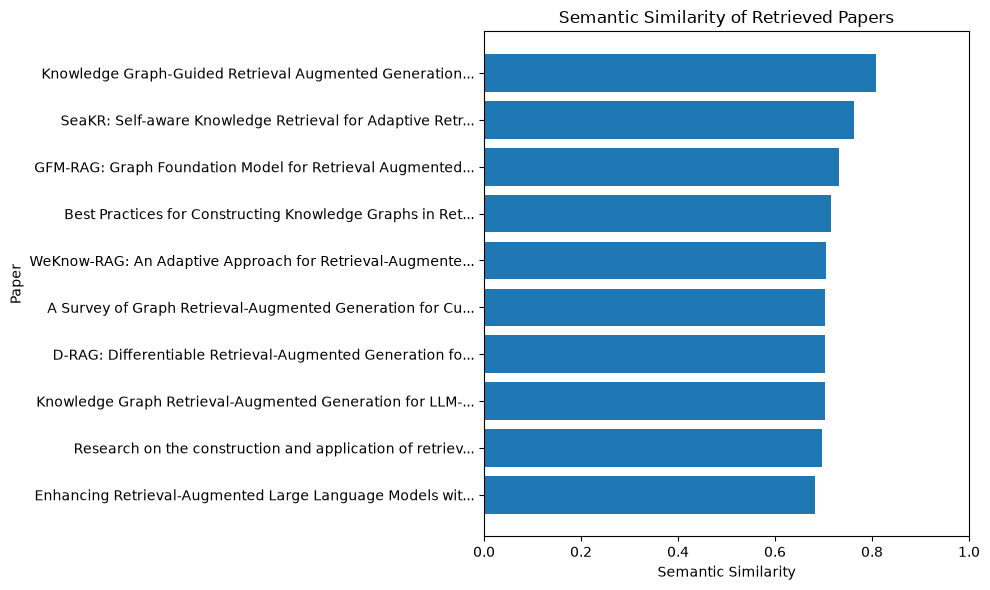

In [22]:
# Cleaner semantic similarity visualization

plot_df = explorer_results.copy()

# Shorten long titles for visualization only
plot_df["short_title"] = (
    plot_df["title"]
    .str.slice(0, 55)
    .str.rstrip()
    + "..."
)

plot_df = plot_df.sort_values("similarity")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["short_title"],
    plot_df["similarity"]
)

plt.xlabel("Semantic Similarity")
plt.ylabel("Paper")
plt.title("Semantic Similarity of Retrieved Papers")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

community,6,17,51
topic_name,,,
Computational Linguistics,0,1,0
Core RAG & Retrieval,2,0,0
Graph RAG & Knowledge Graphs,2,0,0
NLP / Computational Linguistics,1,2,0
Question Answering & Retrieval,0,0,1
Surveys & Research Directions,1,0,0


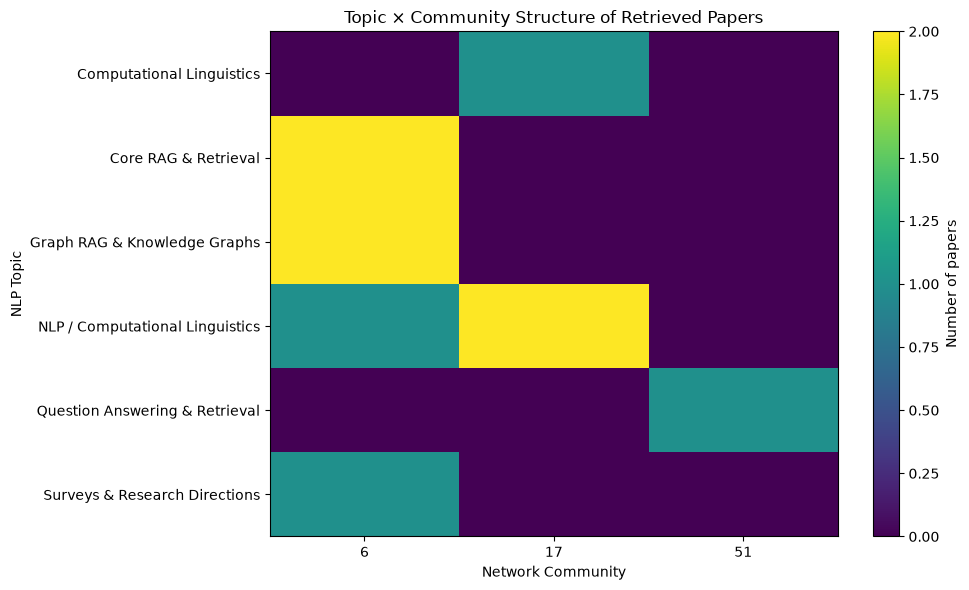

In [24]:
# Topic × Community structure of retrieved papers

topic_community = pd.crosstab(
    explorer_results["topic_name"],
    explorer_results["community"]
)

display(topic_community)

plt.figure(figsize=(10, 6))

plt.imshow(
    topic_community.values,
    aspect="auto"
)

plt.colorbar(label="Number of papers")

plt.xticks(
    range(len(topic_community.columns)),
    topic_community.columns
)

plt.yticks(
    range(len(topic_community.index)),
    topic_community.index
)

plt.xlabel("Network Community")
plt.ylabel("NLP Topic")
plt.title("Topic × Community Structure of Retrieved Papers")

plt.tight_layout()
plt.show()

# Research Explorer — Summary

The Research Explorer combines semantic search, NLP topic modeling, and research-network structure to investigate a natural-language research query.

### Explorer workflow

**Research query**
→ **Sentence-Transformer semantic search**
→ **Top matching papers**
→ **NLP topic distribution**
→ **Network community distribution**
→ **Network and citation context**

### Key capabilities

- Retrieve semantically related research papers from the corpus
- Identify the NLP topics represented in retrieved papers
- Identify the network communities reached by a query
- Compare semantic similarity with network structure
- Examine citation and centrality characteristics of retrieved papers
- Visualize the relationship between NLP topics and network communities

### Interpretation

The explorer demonstrates that semantic similarity and network structure provide complementary views of the research landscape. A single research query can retrieve papers spanning multiple NLP topics and network communities, revealing connections that may not be captured by either representation alone.

### Important limitations

- The corpus contains 767 embedded papers.
- Semantic similarity depends on the selected embedding model.
- NMF topic labels are corpus-specific and represent exploratory topics.
- Network communities depend on the graph construction threshold and community-detection method.
- Citation counts are affected by publication year and citation-window differences.
- Search results describe relationships within this corpus and should not be interpreted as a complete representation of the entire RAG literature.

In [25]:
# Final Research Explorer validation

print("Research Explorer validation")
print("-" * 40)

print(f"Research papers: {len(research_df)}")
print(f"Embedding dimensions: {embeddings.shape}")
print(f"Topics represented: {research_df['topic_name'].nunique()}")
print(f"Network communities represented: {research_df['community'].nunique()}")

print("\nExplorer function:", callable(explore_research))
print("Semantic search function:", callable(search_papers))

print("\nNotebook 06 validation complete.")

Research Explorer validation
----------------------------------------
Research papers: 767
Embedding dimensions: (767, 384)
Topics represented: 10
Network communities represented: 124

Explorer function: True
Semantic search function: True

Notebook 06 validation complete.
